In [ ]:
import sys
import os

sys.path.append(os.path.abspath('..'))

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from src.dataset import get_dataloaders

print("Loading Model...")
model = tf.keras.models.load_model('../models/attention_unet_best_model.keras')
_, _, class_names = get_dataloaders('../data/images/', '../data/annotations/trimaps/', batch_size=2)
print("Demo Environment Ready!")

Loading Model...
Demo Environment Ready!


In [ ]:
def predict_and_plot(image_path, model, class_names):
    """Loads a random image from a file path, preprocesses it, and plots predictions."""
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (128, 128))
    img = img / 255.0

    img_batch = tf.expand_dims(img, axis=0)

    pred_mask, pred_label = model.predict(img_batch, verbose=0)

    binary_mask = (pred_mask[0] > 0.5).astype(np.float32)
    predicted_breed = class_names[np.argmax(pred_label[0])]
    confidence = np.max(pred_label[0]) * 100
 
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    axes[0].imshow(img.numpy())
    axes[0].set_title(f"Input Image\nPredicted: {predicted_breed} ({confidence:.1f}%)", fontweight='bold')
    axes[0].axis('off')
    
    axes[1].imshow(binary_mask, cmap='gray')
    axes[1].set_title("Predicted Attention Mask", fontweight='bold')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

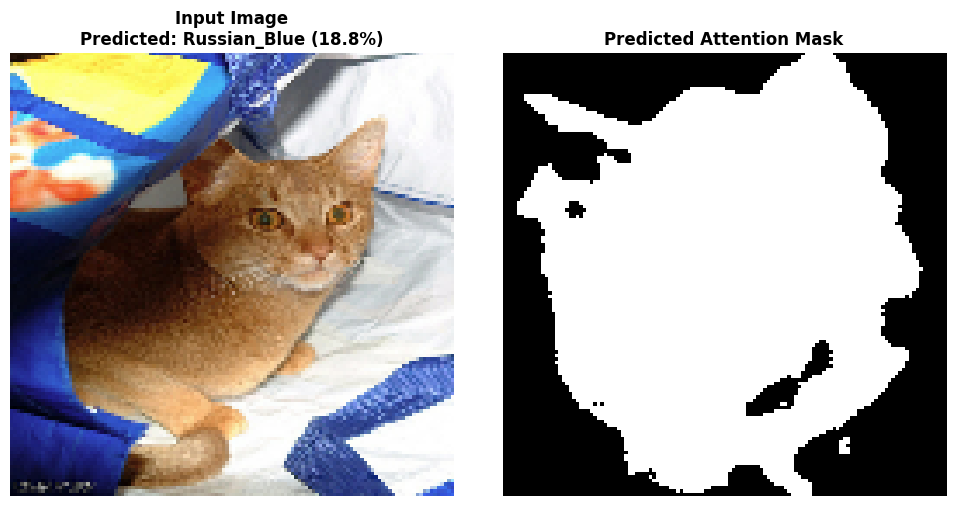

In [4]:
test_image_path = '../data/images/Abyssinian_100.jpg' 

predict_and_plot(test_image_path, model, class_names)